# Tech Challenge Fase 1 — Case E-commerce Olist

**Pós Tech Data Analytics — FIAP** · Caio Henrique F. de J. Sousa - rm377563

### Perguntas que irei responder atráves desta análise:
1. **A Olist está crescendo?** Pedidos, receita e ticket médio por mês.
2. **Onde e o que se vende?** Estados, regiões e categorias.
3. **A entrega chega no prazo?** Tempo de entrega e atrasos.
4. **O que deixa o cliente satisfeito?** Nota da avaliação x atraso, preço e frete.
5. **O cliente volta a comprar?** Recompra e meios de pagamento.

E no final, uma **projeção simples** para a Black Friday de 2018.

## Resumo executivo

- A receita cresceu **141%** (jan–ago 2018 vs 2017), mas **estabilizou** em 2018.
- Pedido **atrasado** recebe nota **2,3** contra **4,3** no prazo — atraso é o que mais tira satisfação.
- Só **3%** dos clientes compram de novo.
- O **Nordeste** é o maior espaço de crescimento, mas tem o dobro de atraso.
- Projeção: novembro/2018 perto de **R&#36; 1,4 mi** (Black Friday).

## 1. Preparando o ambiente

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

# pasta onde estão os CSVs do Kaggle + o CSV do IBGE
PASTA = "../data/externos/"

# estilo dos gráficos: 
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "grid.color": "#e6e6e3",
})
AZUL = "#2a78d6"      # cor principal 
LARANJA = "#eb6834"   # cor de destaque
CINZA = "#a3a29c"     # contexto

pd.options.display.float_format = "{:,.2f}".format

## 2. Carregando os dados

O dataset tem 9 tabelas ligadas por chaves (`order_id`, `customer_id`, `product_id`, `seller_id`). Também trouxe um **dado externo**: a população por estado em 2018 (IBGE), para comparar o tamanho do mercado de cada região.

In [2]:
datas = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
         "order_delivered_customer_date", "order_estimated_delivery_date"]

pedidos    = pd.read_csv(PASTA + "olist_orders_dataset.csv", parse_dates=datas)
itens      = pd.read_csv(PASTA + "olist_order_items_dataset.csv")
clientes   = pd.read_csv(PASTA + "olist_customers_dataset.csv")
pagamentos = pd.read_csv(PASTA + "olist_order_payments_dataset.csv")
avaliacoes = pd.read_csv(PASTA + "olist_order_reviews_dataset.csv", parse_dates=["review_answer_timestamp"])
produtos   = pd.read_csv(PASTA + "olist_products_dataset.csv")
vendedores = pd.read_csv(PASTA + "olist_sellers_dataset.csv")
traducao   = pd.read_csv(PASTA + "product_category_name_translation.csv")
populacao  = pd.read_csv(PASTA + "populacao_uf_2018.csv")   # dado externo (IBGE)

tabelas = {"pedidos": pedidos, "itens": itens, "clientes": clientes, "pagamentos": pagamentos,
           "avaliacoes": avaliacoes, "produtos": produtos, "vendedores": vendedores}
pd.DataFrame({nome: [df.shape[0], df.shape[1]] for nome, df in tabelas.items()},
             index=["linhas", "colunas"]).T

,linhas,colunas
pedidos,99441,8
itens,112650,7
clientes,99441,5
pagamentos,103886,5
avaliacoes,99224,7
produtos,32951,9
vendedores,3095,4


In [3]:
pedidos.head(4)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15


## 3. Qualidade dos dados

Validando 3 infos: **valores vazios**, **status dos pedidos** e **período coberto**.

In [4]:
# quantos valores vazios em cada coluna 
nulos = pedidos.isna().sum()
nulos[nulos > 0].to_frame("vazios")

,vazios
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965


**Info importante**: As datas de entrega vazias são de pedidos que **não foram entregues** (cancelados, em trânsito etc.). E isso faz sentido, não é erro.

In [5]:
(pedidos["order_status"].value_counts(normalize=True) * 100).round(2).to_frame("% dos pedidos")

,% dos pedidos
order_status,
delivered,97.02
shipped,1.11
canceled,0.63
unavailable,0.61
invoiced,0.32
processing,0.30
created,0.01
approved,0.00


97% Dos pedidos estão foram entregues conforme tabela acima. 

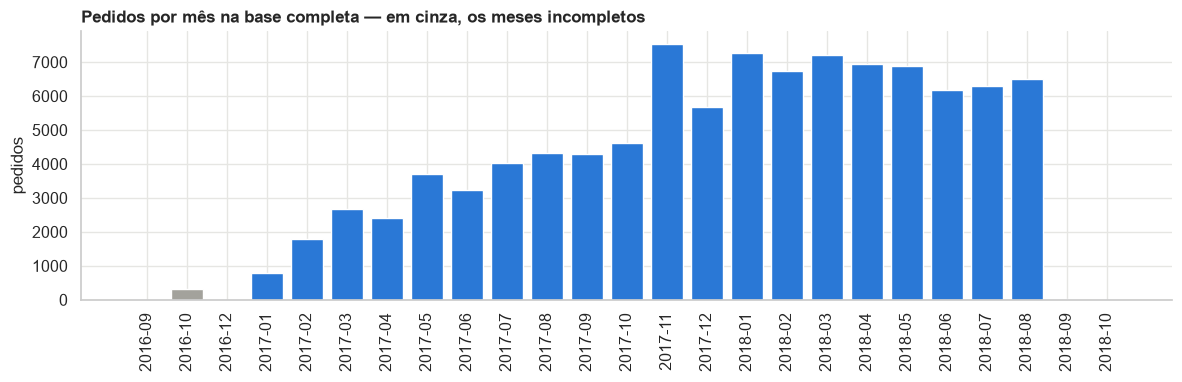

In [6]:
por_mes = pedidos.groupby(pedidos["order_purchase_timestamp"].dt.to_period("M")).size()

fig, ax = plt.subplots(figsize=(12, 4))
cores = [CINZA if (m < pd.Period("2017-01", "M") or m > pd.Period("2018-08", "M")) else AZUL for m in por_mes.index]
ax.bar(por_mes.index.astype(str), por_mes.values, color=cores)
ax.set_title("Pedidos por mês na base completa — em cinza, os meses incompletos")
ax.set_ylabel("pedidos")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

O começo (2016) e o fim (set–out/2018) têm pouquíssimos pedidos: o dataset foi cortado. Se mantivermos esses meses, os gráficos mostrariam uma "queda" que não aconteceu.

### Decisões de limpeza

| Decisão | Por quê |
|---|---|
| Analisar **jan/2017 a ago/2018** (20 meses) | as pontas estão incompletas |
| Usar só pedidos entregues (`delivered`) | cancelados não geram receita nem entrega |
| Receita = soma do preço dos itens (sem frete) | o frete é repassado à transportadora |
| Somar os itens antes de juntar com pedidos | um pedido pode ter vários itens |
| Ficar com 1 avaliação por pedido (a mais recente) | há pedidos avaliados mais de uma vez |
| Cliente = `customer_unique_id` | o `customer_id` muda a cada compra |

## 4. Montando a base de análise

Uma linha por pedido, com receita, frete, cliente, nota e os tempos de entrega.

In [7]:
# 1) filtra período e status
base = pedidos[(pedidos["order_purchase_timestamp"] >= "2017-01-01") &
               (pedidos["order_purchase_timestamp"] <  "2018-09-01") &
               (pedidos["order_status"] == "delivered")].copy()

# 2) soma os itens por pedido ANTES do join (evita duplicar)
itens_pedido = itens.groupby("order_id").agg(receita=("price", "sum"),
                                             frete=("freight_value", "sum"),
                                             qtd_itens=("order_item_id", "count")).reset_index()
base = base.merge(itens_pedido, on="order_id", how="inner")

# 3) dados do cliente
base = base.merge(clientes, on="customer_id", how="left")

# 4) uma avaliação por pedido (a mais recente)
aval = avaliacoes.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")
base = base.merge(aval[["order_id", "review_score"]], on="order_id", how="left")

# 5) colunas novas
base["mes"] = base["order_purchase_timestamp"].dt.to_period("M")
base["dias_entrega"] = (base["order_delivered_customer_date"] - base["order_purchase_timestamp"]).dt.days
base["dias_prometido"] = (base["order_estimated_delivery_date"] - base["order_purchase_timestamp"]).dt.days
base["dias_atraso"] = (base["order_delivered_customer_date"].dt.normalize() - base["order_estimated_delivery_date"]).dt.days
base["atrasado"] = base["dias_atraso"] > 0

regiao = {"SP": "Sudeste", "RJ": "Sudeste", "MG": "Sudeste", "ES": "Sudeste",
          "PR": "Sul", "SC": "Sul", "RS": "Sul",
          "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
          "BA": "Nordeste", "PE": "Nordeste", "CE": "Nordeste", "MA": "Nordeste", "PB": "Nordeste",
          "RN": "Nordeste", "AL": "Nordeste", "SE": "Nordeste", "PI": "Nordeste",
          "PA": "Norte", "AM": "Norte", "RO": "Norte", "TO": "Norte", "AC": "Norte", "AP": "Norte", "RR": "Norte"}
base["regiao"] = base["customer_state"].map(regiao)

# conferência: 1 linha por pedido?
assert base["order_id"].is_unique
print(f"{len(base):,} pedidos | {base['customer_unique_id'].nunique():,} clientes | "
      f"receita total R$ {base['receita'].sum()/1e6:,.2f} mi")
base[["order_id", "customer_state", "receita", "frete", "dias_entrega", "atrasado", "review_score"]].head()

96,211 pedidos | 93,104 clientes | receita total R$ 13.18 mi


,order_id,customer_state,receita,frete,dias_entrega,atrasado,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,29.99,8.72,8.00,False,4.00
1,53cdb2fc8bc7dce0b6741e2150273451,BA,118.70,22.76,13.00,False,4.00
2,47770eb9100c2d0c44946d9cf07ec65d,GO,159.90,19.22,9.00,False,5.00
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,45.00,27.20,13.00,False,5.00
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,19.90,8.72,2.00,False,5.00


## 5. Análise

### Pergunta 1 — A Olist está crescendo?

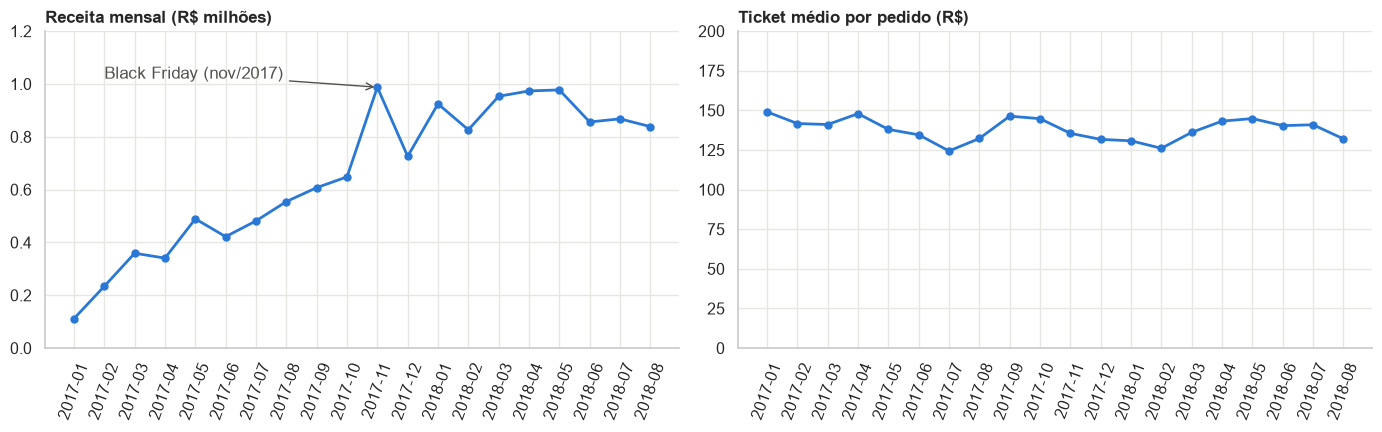

In [8]:
#ticket médio é receita ÷ pedidos, ou seja, quanto cada pedido vale em média.

mensal = base.groupby("mes").agg(pedidos=("order_id", "count"), receita=("receita", "sum"))
mensal["ticket_medio"] = mensal["receita"] / mensal["pedidos"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = mensal.index.astype(str)

axes[0].plot(x, mensal["receita"] / 1e6, color=AZUL, lw=2, marker="o", ms=5)
axes[0].set_ylim(0, 1.2)
axes[0].set_title("Receita mensal (R$ milhões)")
axes[0].annotate("Black Friday (nov/2017)", xy=(10, mensal["receita"].iloc[10] / 1e6),
                 xytext=(1, 1.02), arrowprops=dict(arrowstyle="->", color="#52514e"), color="#52514e")

axes[1].plot(x, mensal["ticket_medio"], color=AZUL, lw=2, marker="o", ms=5)
axes[1].set_ylim(0, 200)
axes[1].set_title("Ticket médio por pedido (R$)")

for ax in axes:
    ax.tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

In [9]:
# comparando o mesmo período (jan-ago) dos dois anos
#Por que só jan–ago? A base de 2018 termina em agosto. Se comparar 2017 inteiro (12 meses) com 2018 (8 meses), 2018 pareceria menor só porque tem menos meses.
def periodo(ano):
    b = base[(base["order_purchase_timestamp"].dt.year == ano) & (base["order_purchase_timestamp"].dt.month <= 8)]
    return pd.Series({"pedidos": len(b), "receita (R$ mi)": b["receita"].sum() / 1e6, "ticket médio (R$)": b["receita"].mean()})

comparativo = pd.DataFrame({"jan-ago 2017": periodo(2017), "jan-ago 2018": periodo(2018)})
comparativo["variação %"] = (comparativo["jan-ago 2018"] / comparativo["jan-ago 2017"] - 1) * 100
comparativo.round(1)

,jan-ago 2017,jan-ago 2018,variação %
pedidos,"21,998.00","52,783.00",139.90
receita (R$ mi),3.00,7.20,141.10
ticket médio (R$),136.10,136.80,0.50


**O que vimos**
- A receita de jan–ago/2018 foi **141% maior** que no mesmo período de 2017 (R&#36; 2,99 mi → R&#36; 7,22 mi).
- O crescimento veio do **número de pedidos** (+140%). O **ticket médio ficou parado** em ~R&#36; 137: o cliente não está gastando mais por compra.
- O pico de **nov/2017** é a Black Friday (quase R&#36; 1 mi no mês).
- Em 2018 a receita **parou de subir** e ficou estável perto de R&#36; 0,9 mi por mês. O próximo ciclo de crescimento precisa de algo novo.

### Pergunta 2 — Onde e o que se vende?

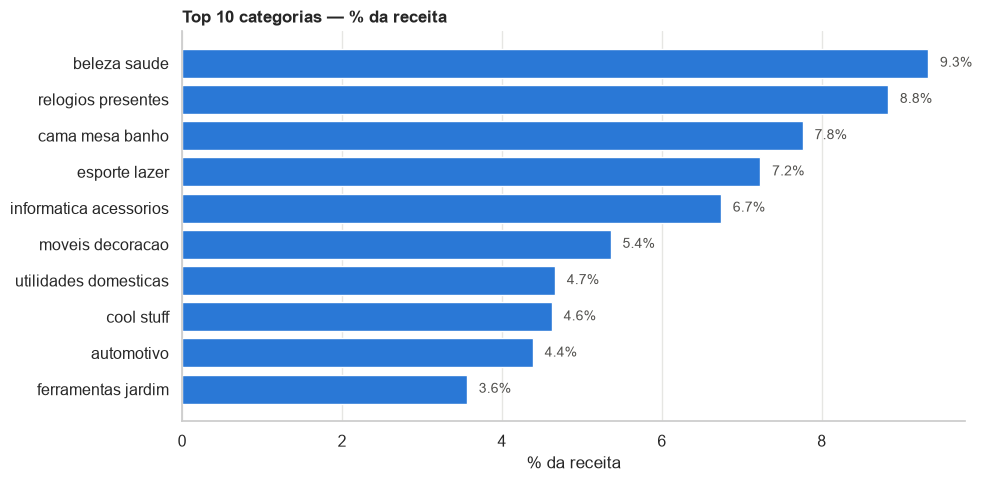

As 10 maiores categorias somam 62% da receita, de 74 categorias.


In [22]:
# receita por categoria 
cat = itens.merge(produtos[["product_id", "product_category_name"]], on="product_id", how="left")
cat = cat[cat["order_id"].isin(base["order_id"])]
cat["categoria"] = cat["product_category_name"].fillna("sem_categoria").str.replace("_", " ")
top_cat = cat.groupby("categoria")["price"].sum().sort_values(ascending=False)
share_cat = top_cat / top_cat.sum() * 100

fig, ax = plt.subplots(figsize=(10, 5))
top10 = share_cat.head(10).sort_values()
ax.barh(top10.index, top10.values, color=AZUL)
for i, v in enumerate(top10.values):
    ax.text(v + 0.15, i, f"{v:.1f}%", va="center", fontsize=10, color="#52514e")
ax.set_title("Top 10 categorias — % da receita")
ax.set_xlabel("% da receita")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"As 10 maiores categorias somam {share_cat.head(10).sum():.0f}% da receita, de {len(share_cat)} categorias.")

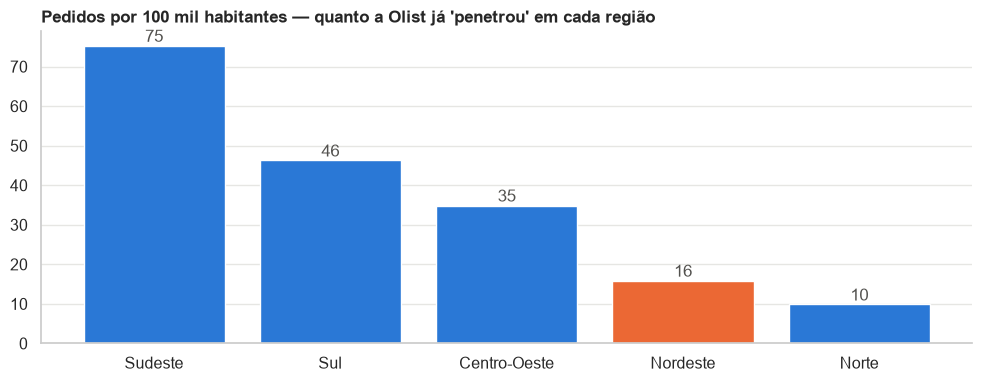

,% pedidos,% população,pedidos por 100 mil hab.
regiao,,,
Sudeste,68.60,42.10,75.30
Sul,14.30,14.30,46.30
Centro-Oeste,5.80,7.70,34.90
Nordeste,9.40,27.20,15.90
Norte,1.90,8.70,9.90


In [26]:
# receita e pedidos por região, comparando com a população (dado externo IBGE)
#Por que não basta contar pedidos por região? O Sudeste sempre vai ter mais pedidos, porque tem mais gente. 
#Para comparar de forma justa, é preciso ver quantos pedidos existem para cada grupo de pessoas
populacao["regiao"] = populacao["uf"].map(regiao)
reg = base.groupby("regiao").agg(pedidos=("order_id", "count"), receita=("receita", "sum"))
reg["populacao"] = populacao.groupby("regiao")["populacao"].sum()
reg["% pedidos"] = reg["pedidos"] / reg["pedidos"].sum() * 100
reg["% população"] = reg["populacao"] / reg["populacao"].sum() * 100
reg["pedidos por 100 mil hab."] = reg["pedidos"] / reg["populacao"] * 1e5
reg = reg.sort_values("pedidos por 100 mil hab.", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
cores = [LARANJA if r == "Nordeste" else AZUL for r in reg.index]
ax.bar(reg.index, reg["pedidos por 100 mil hab."], color=cores)
for i, v in enumerate(reg["pedidos por 100 mil hab."]):
    ax.text(i, v + 1, f"{v:.0f}", ha="center", color="#52514e")
ax.set_title("Pedidos por 100 mil habitantes — quanto a Olist já conquistou em cada região")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
reg[["% pedidos", "% população", "pedidos por 100 mil hab."]].round(1)

In [27]:
uf = base.groupby("customer_state")["receita"].sum().sort_values(ascending=False)
print(f"SP, RJ e MG = {uf.head(3).sum() / uf.sum() * 100:.0f}% da receita")
print(f"Vendedores em SP = {(vendedores['seller_state'] == 'SP').mean() * 100:.0f}% de todos os vendedores")

SP, RJ e MG = 63% da receita
Vendedores em SP = 60% de todos os vendedores


**O que vimos**
- A receita é **bem distribuída** entre categorias: a maior (beleza e saúde) tem só 9%. Não há dependência de um único produto.
- **SP, RJ e MG = 63% da receita**, e **60% dos vendedores estão em SP**.
- Usando a população do IBGE: o **Nordeste** tem 27% da população do país, mas só 9% dos pedidos (16 pedidos por 100 mil habitantes, contra 75 no Sudeste). É a região com **mais espaço para crescer**.

### Pergunta 3 — A entrega chega no prazo?

Tempo médio de entrega: 12.1 dias
Prazo médio prometido:  23.3 dias
Pedidos atrasados:      6.8%


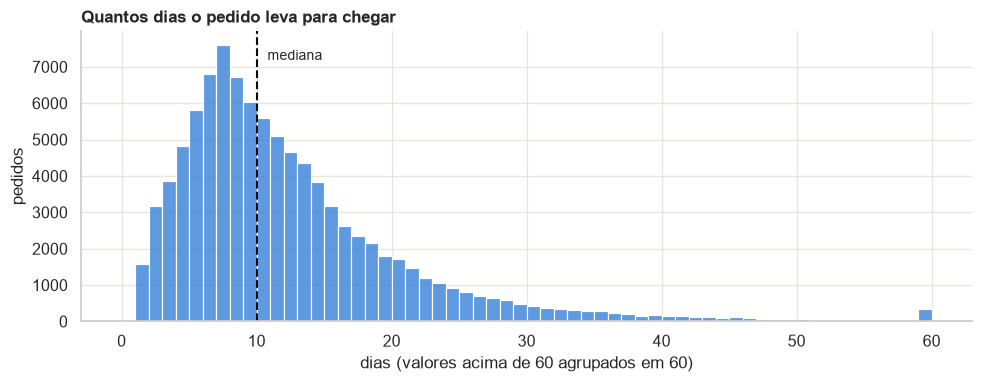

In [13]:
print(f"Tempo médio de entrega: {base['dias_entrega'].mean():.1f} dias")
print(f"Prazo médio prometido:  {base['dias_prometido'].mean():.1f} dias")
print(f"Pedidos atrasados:      {base['atrasado'].mean() * 100:.1f}%")

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(base["dias_entrega"].clip(upper=60), bins=60, color=AZUL, ax=ax)
ax.axvline(base["dias_entrega"].median(), color="#0b0b0b", ls="--", lw=1.5)
ax.text(base["dias_entrega"].median() + 0.8, ax.get_ylim()[1] * 0.9, "mediana", fontsize=10)
ax.set_title("Quantos dias o pedido leva para chegar")
ax.set_xlabel("dias (valores acima de 60 agrupados em 60)")
ax.set_ylabel("pedidos")
plt.tight_layout()
plt.show()

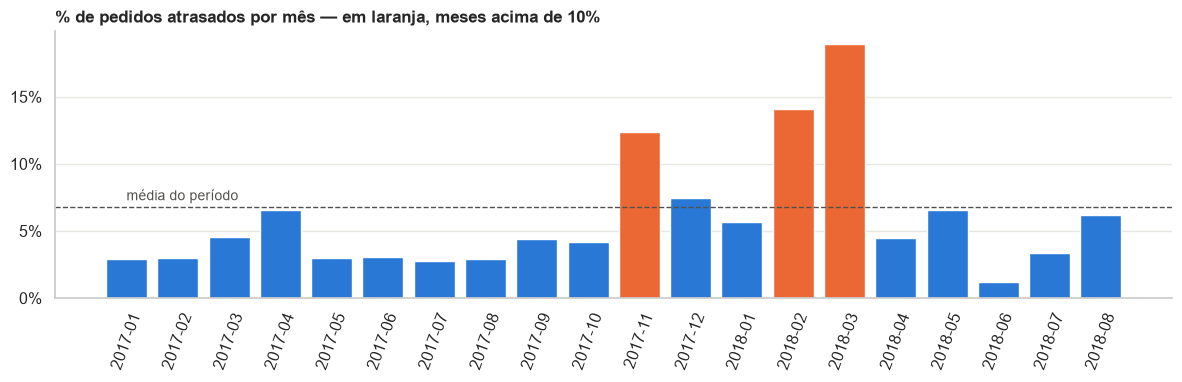

In [14]:
atraso_mes = base.groupby("mes")["atrasado"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 4))
cores = [LARANJA if v > 10 else AZUL for v in atraso_mes.values]
ax.bar(atraso_mes.index.astype(str), atraso_mes.values, color=cores)
ax.axhline(base["atrasado"].mean() * 100, color="#52514e", ls="--", lw=1)
ax.text(0, base["atrasado"].mean() * 100 + 0.5, "média do período", fontsize=10, color="#52514e")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_locator(mtick.MultipleLocator(5))
ax.set_title("% de pedidos atrasados por mês — em laranja, meses acima de 10%")
ax.tick_params(axis="x", rotation=70)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [15]:
reg_log = base.groupby("regiao").agg(atraso_pct=("atrasado", "mean"), dias_entrega=("dias_entrega", "mean"),
                                     nota_media=("review_score", "mean"))
reg_log["atraso_pct"] *= 100
reg_log.sort_values("atraso_pct", ascending=False)

,atraso_pct,dias_entrega,nota_media
regiao,,,
Nordeste,12.76,19.52,3.97
Norte,8.60,22.14,4.03
Centro-Oeste,6.54,14.56,4.13
Sudeste,6.13,10.27,4.18
Sul,5.92,13.55,4.19


**O que vimos**
- O pedido leva **12 dias** em média, mas a Olist promete **23 dias**. A folga é grande, e mesmo assim **6,8%** dos pedidos atrasam.
- O atraso **dispara quando o volume sobe**: 12% na Black Friday de nov/2017 e **19% em mar/2018**.
- O **Nordeste** tem o dobro de atraso do Sul/Sudeste (12,8% x ~6%) e entregas quase 2x mais lentas. Faz sentido: os vendedores estão concentrados em SP.

### Pergunta 4 — O que deixa o cliente satisfeito?

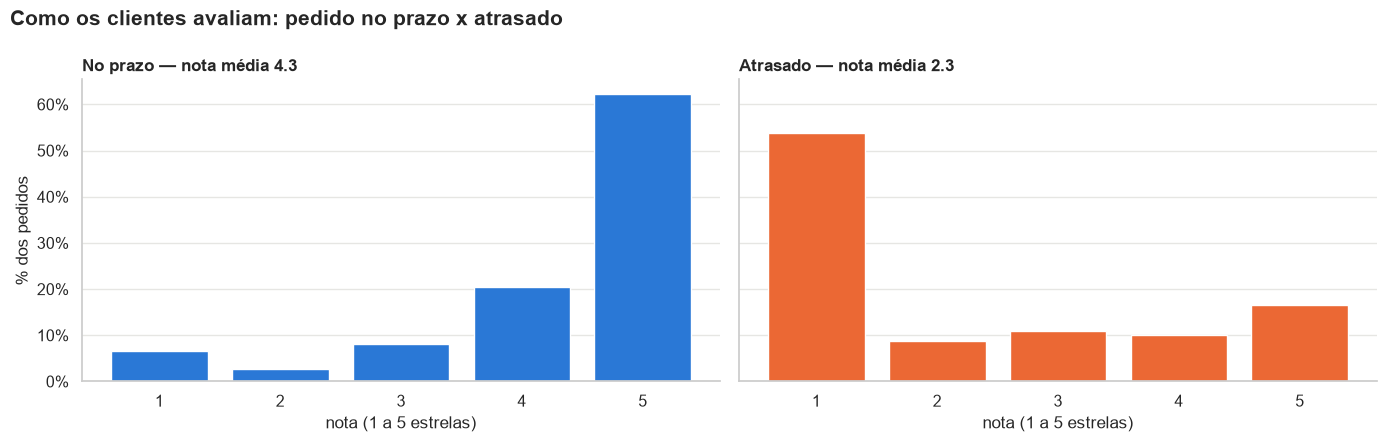

,nota_media,pct_nota_1_ou_2,pedidos
entrega,,,
Atrasado,2.27,62.42,6378
No prazo,4.29,9.25,89190


In [16]:
aval_base = base.dropna(subset=["review_score"]).copy()
aval_base["review_score"] = aval_base["review_score"].astype(int)
aval_base["entrega"] = np.where(aval_base["atrasado"], "Atrasado", "No prazo")

dist = (pd.crosstab(aval_base["entrega"], aval_base["review_score"], normalize="index") * 100).loc[["No prazo", "Atrasado"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, grupo, cor in zip(axes, dist.index, [AZUL, LARANJA]):
    ax.bar(dist.columns.astype(int).astype(str), dist.loc[grupo], color=cor)
    ax.set_title(f"{grupo} — nota média {aval_base.loc[aval_base['entrega'] == grupo, 'review_score'].mean():.1f}")
    ax.set_xlabel("nota (1 a 5 estrelas)")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% dos pedidos")
plt.suptitle("Como os clientes avaliam: pedido no prazo x atrasado", fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

resumo_nota = aval_base.groupby("entrega").agg(nota_media=("review_score", "mean"),
                                               pct_nota_1_ou_2=("review_score", lambda s: (s <= 2).mean() * 100),
                                               pedidos=("review_score", "size"))
resumo_nota

In [17]:
# teste estatístico: a diferença de nota é real ou poderia ser sorte?
no_prazo = aval_base.loc[~aval_base["atrasado"], "review_score"]
atrasado = aval_base.loc[aval_base["atrasado"], "review_score"]
_, p = stats.mannwhitneyu(no_prazo, atrasado)
print(f"p-valor = {p:.1e} -> {'diferença significativa' if p < 0.05 else 'sem diferença'}")

p-valor = 0.0e+00 -> diferença significativa


O **p-valor** quase zero indica que a diferença não é acaso: atraso realmente derruba a nota.

Agora, o que mais pesa na nota? Usamos a **correlação de Spearman** (vai de -1 a 1; quanto mais longe de zero, mais forte a relação; negativo = quando um sobe, o outro desce).

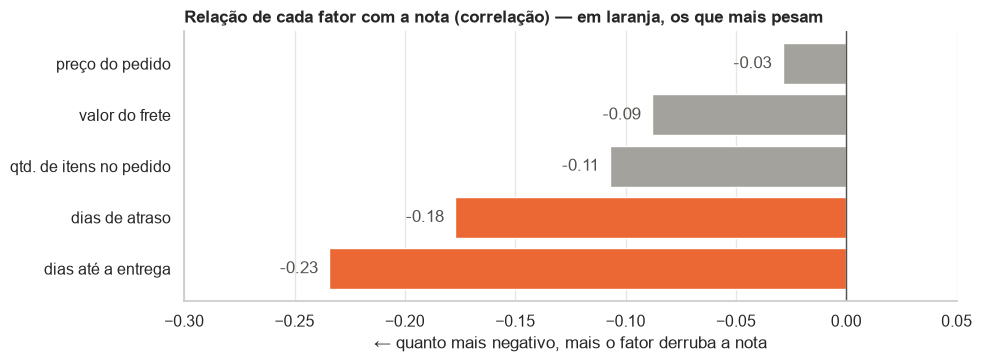

In [18]:
nomes = {"dias_atraso": "dias de atraso", "dias_entrega": "dias até a entrega",
         "qtd_itens": "qtd. de itens no pedido", "frete": "valor do frete", "receita": "preço do pedido"}
corr = (aval_base[["review_score"] + list(nomes)].corr(method="spearman")["review_score"]
        .drop("review_score").rename(nomes).sort_values())

fig, ax = plt.subplots(figsize=(10, 3.8))
cores = [LARANJA if v <= -0.15 else CINZA for v in corr.values]
ax.barh(corr.index, corr.values, color=cores)
for i, v in enumerate(corr.values):
    ax.text(v - 0.005, i, f"{v:.2f}", va="center", ha="right", color="#52514e")
ax.set_xlim(-0.3, 0.05)
ax.axvline(0, color="#52514e", lw=1)
ax.set_title("Relação de cada fator com a nota (correlação) — em laranja, os que mais pesam")
ax.set_xlabel("← quanto mais negativo, mais o fator derruba a nota")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**O que vimos**
- **Atraso é o que mais derruba a satisfação.** No prazo, a nota média é **4,3**; atrasado, cai para **2,3**, e **62%** dos atrasados dão nota 1 ou 2 (contra 9% no prazo).
- O teste estatístico confirma que a diferença não é acaso.
- No gráfico de correlação, **tempo de entrega e atraso** são os fatores que mais pesam.
- **Preço e frete quase não influenciam** a nota (correlação perto de zero). O cliente aceita pagar, mas não aceita esperar além do prometido.

### Pergunta 5 — O cliente volta a comprar? Como ele paga?

93,104 clientes únicos — só 3.0% compraram mais de uma vez


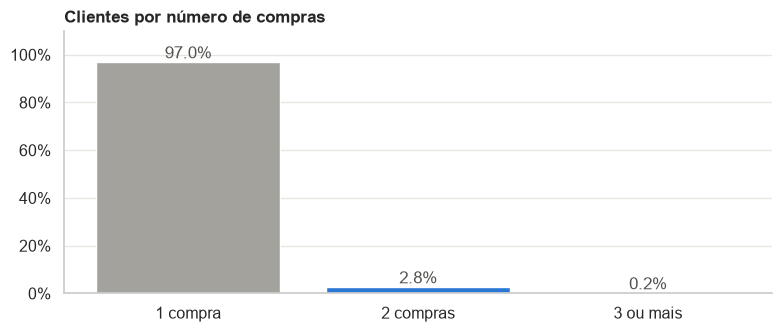

In [19]:
compras = base.groupby("customer_unique_id")["order_id"].count()
recompra = (compras > 1).mean() * 100
print(f"{len(compras):,} clientes únicos — só {recompra:.1f}% compraram mais de uma vez")

fig, ax = plt.subplots(figsize=(8, 3.5))
faixas = compras.clip(upper=3).value_counts(normalize=True).sort_index() * 100
ax.bar(["1 compra", "2 compras", "3 ou mais"], faixas.values, color=[CINZA, AZUL, AZUL])
for i, v in enumerate(faixas.values):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha="center", color="#52514e")
ax.set_ylim(0, 110)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Clientes por número de compras")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [20]:
pag = pagamentos[pagamentos["order_id"].isin(base["order_id"])]
meio = pag.groupby("payment_type")["payment_value"].sum().sort_values(ascending=False)
meio = (meio / meio.sum() * 100).rename({"credit_card": "cartão de crédito", "boleto": "boleto",
                                         "voucher": "voucher", "debit_card": "cartão de débito"})
cartao = pag[pag["payment_type"] == "credit_card"]
print(f"Compras no cartão parceladas (2x ou mais): {(cartao['payment_installments'] > 1).mean() * 100:.0f}%")
print(f"Média de parcelas no cartão: {cartao['payment_installments'].mean():.1f}")
meio.round(1).to_frame("% do valor pago")

Compras no cartão parceladas (2x ou mais): 67%
Média de parcelas no cartão: 3.5


,% do valor pago
payment_type,
cartão de crédito,78.50
boleto,18.00
voucher,2.20
cartão de débito,1.40


**O que vimos**
- Apenas **3% dos clientes compraram mais de uma vez**. A receita depende quase toda de **conquistar cliente novo**, o que é caro.
- **Cartão de crédito = 78%** do valor pago, e **67%** das compras no cartão são parceladas (3,5 parcelas em média). Parcelamento é parte importante da decisão de compra.

## 6. Projeção simples: quanto esperar até dez/2018?

1. **Base:** média de receita dos últimos 4 meses (mai–ago/2018), porque em 2018 a receita estabilizou.
2. **Sazonalidade:** quanto nov e dez/2017 venderam acima da média de set–out/2017 (efeito Black Friday e Natal).
3. **Validação:** teste da lógica no passado (média de jan–abr/2018 prevendo mai–ago/2018) para medir o erro.

Erro médio da lógica no teste (mai-ago/2018): 7.2%
Novembro vende 1.57x um mês normal | Dezembro 1.16x


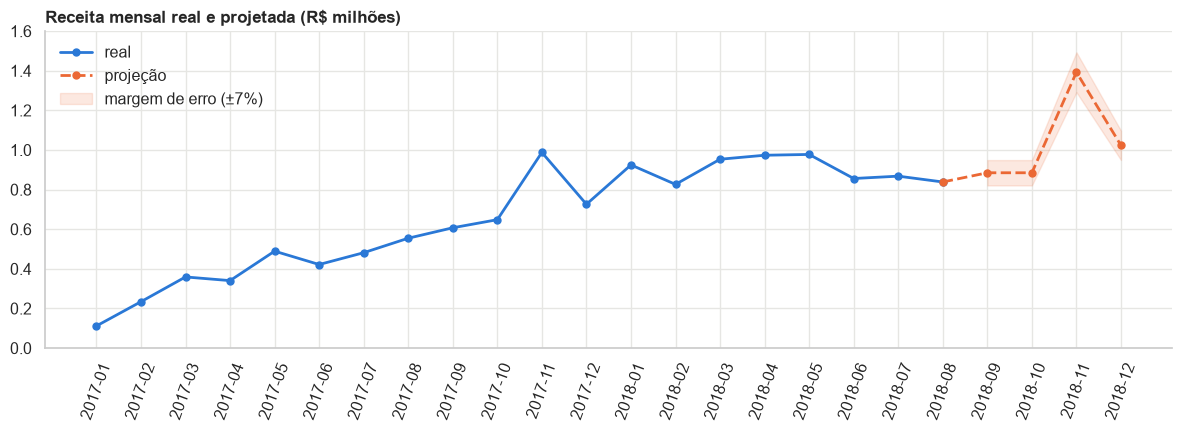

Projeção set-dez/2018: R$ 4.2 mi | novembro: R$ 1.39 mi


In [21]:
receita = mensal["receita"]

# validação: quanto essa lógica erraria no passado?
prev_teste = receita["2018-01":"2018-04"].mean()
real_teste = receita["2018-05":"2018-08"]
erro = (abs(real_teste - prev_teste) / real_teste).mean()
print(f"Erro médio da lógica no teste (mai-ago/2018): {erro * 100:.1f}%")

# fatores de sazonalidade de 2017
base_17 = receita["2017-09":"2017-10"].mean()
fator_nov = receita["2017-11"] / base_17
fator_dez = receita["2017-12"] / base_17
print(f"Novembro vende {fator_nov:.2f}x um mês normal | Dezembro {fator_dez:.2f}x")

media_recente = receita["2018-05":"2018-08"].mean()
futuro = pd.Series([media_recente, media_recente, media_recente * fator_nov, media_recente * fator_dez],
                   index=pd.period_range("2018-09", periods=4, freq="M"))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(receita.index.astype(str), receita / 1e6, color=AZUL, lw=2, marker="o", ms=5, label="real")
ligacao = pd.concat([receita.iloc[-1:], futuro])   # liga o último mês real à projeção
ax.plot(ligacao.index.astype(str), ligacao / 1e6, color=LARANJA, lw=2, ls="--", marker="o", ms=5, label="projeção")
ax.fill_between(futuro.index.astype(str), futuro / 1e6 * (1 - erro), futuro / 1e6 * (1 + erro),
                color=LARANJA, alpha=0.15, label=f"margem de erro (±{erro * 100:.0f}%)")
ax.set_ylim(0, 1.6)
ax.set_title("Receita mensal real e projetada (R$ milhões)")
ax.tick_params(axis="x", rotation=70)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

print(f"Projeção set-dez/2018: R$ {futuro.sum() / 1e6:.1f} mi | novembro: R$ {futuro['2018-11'] / 1e6:.2f} mi")

**Limitação:** só tem uma Black Friday no histórico, então a projeção é uma **ordem de grandeza**, não um número exato.

## 7. Conclusões e recomendações

| # | Recomendação | Por quê (dado) |
|---|---|---|
| 1 | **Reforçar a logística antes da Black Friday 2018** | Em nov/2017 o atraso triplicou (de ~4% para 12%); a projeção indica novembro ~57% acima de um mês normal |
| 2 | **Prazo máximo de postagem para vendedores** e ranking dos que entregam no prazo | Atraso é o principal motivo de nota baixa (4,3 → 2,3) |
| 3 | **Resolver a entrega no Nordeste antes de investir em marketing lá** (vendedores ou centro de distribuição na região) | Região com mais espaço para crescer (16 x 75 pedidos/100 mil hab.), mas com o pior atraso e a pior nota |
| 4 | **Campanha de segunda compra** (cupom após a entrega) | Só 3% dos clientes voltam; cada recompra é receita sem custo de aquisição |
| 5 | **Manter e destacar o parcelamento** no cartão | 78% do valor é pago no cartão e 2 em cada 3 compras no cartão são parceladas |

**Limitações:** dados de 2017–2018, só uma Black Friday no histórico e não temos custos (não dá para medir lucro).

## 8. Resumo executivo

- **Crescimento forte, mas desacelerando:** +141% de receita em 2018 vs 2017, puxado por volume. Em 2018 a receita estabilizou em cerca de 0,9 milhão de reais por mês.
- **Atraso é o maior risco para a marca:** quem recebe atrasado dá nota 2,3 (vs 4,3). O atraso explode em picos de demanda e no Nordeste.
- **Cliente não volta:** só 3% compram de novo.
- **Oportunidade:** Nordeste é um mercado pouco explorado, desde que a entrega melhore.
- **Próximos meses:** projeção de cerca de 4,2 milhões de reais de set a dez/2018, com novembro perto de 1,4 milhão de reais (±7%).

---
**Fonte dos dados:** [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) · População por UF 2018: IBGE.